# Tema 3 - Laborator 4: Reţele Bayesiene cu `pgmpy`

Cuprins:
1. **Ex. 1** - Problema Monty Hall: formulare, model în `pgmpy`, explicarea codului, verificare prin simulare
2. **Ex. 2** - Diagnostic medical (boală pulmonară): model, inferenţă, calcul cu regula lui Bayes
3. **Ex. 3** - Jocul dintre $J_0$ şi $J_1$: simulare, reţea bayesiană, inferenţă

**Idee centrală:** o reţea bayesiană este un graf orientat fără cicluri în care fiecare nod este o variabilă aleatoare, iar fiecare nod are un tabel de probabilităţi condiţionate (CPD) în funcţie de părinţii lui. Distribuţia comună este produsul acestor tabele:

$$P(X_1,\dots,X_n) = \prod_i P(X_i \mid \text{părinţi}(X_i))$$

`pgmpy` ne permite să definim graful şi tabelele, apoi să punem întrebări de tipul $P(\text{variabilă} \mid \text{evidenţă})$ prin *inferenţă exactă* (algoritmul *Variable Elimination*).

In [1]:
!pip install -q pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 6.1 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# numele clasei s-a schimbat intre versiunile pgmpy
try:
    from pgmpy.models import DiscreteBayesianNetwork as ReteaBayesiana
except ImportError:
    from pgmpy.models import BayesianNetwork as ReteaBayesiana
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

np.random.seed(12)

def deseneaza(muchii, poz, titlu, culori=None, figsize=(7, 3.6)):
    # deseneaza graful retelei (noduri + sageti)
    fig, ax = plt.subplots(figsize=figsize)
    for a, b in muchii:
        ax.annotate("", xy=poz[b], xytext=poz[a],
                    arrowprops=dict(arrowstyle="-|>", lw=2, color="black",
                                    shrinkA=26, shrinkB=26))
    for v, (x, y) in poz.items():
        c = (culori or {}).get(v, "#8ecae6")
        ax.scatter([x], [y], s=2800, color=c, edgecolor="black", zorder=3)
        ax.text(x, y, v, ha="center", va="center", fontsize=10, zorder=4)
    xs = [p[0] for p in poz.values()]
    ys = [p[1] for p in poz.values()]
    ax.set_xlim(min(xs) - 0.7, max(xs) + 0.7)
    ax.set_ylim(min(ys) - 0.7, max(ys) + 0.7)
    ax.axis("off")
    ax.set_title(titlu)
    plt.show()

def tabel(factor, var):
    # transforma rezultatul inferentei intr-un tabel usor de citit
    return pd.Series(factor.values, index=factor.state_names[var], name="probabilitate").round(4)

## Exerciţiul 1: Problema Monty Hall

### Formularea problemei

Într-un joc televizat există **trei uşi**. În spatele uneia se află un premiu (maşina), iar în spatele celorlalte două sunt capre.

1. Concurentul alege o uşă (fără să o deschidă).
2. Prezentatorul (Monty Hall), care **ştie unde este premiul**, deschide una dintre celelalte două uşi, **întotdeauna una cu capră**.
3. Concurentul este întrebat: *îşi păstrează uşa sau o schimbă cu cealaltă uşă închisă?*

Întrebarea este dacă e mai bine să **schimbi**. Intuiţia spune că rămân două uşi, deci şansele sunt 50-50. Răspunsul corect este însă că **dacă schimbi, câştigi cu probabilitatea 2/3**, iar dacă rămâi, cu 1/3.

### De ce este o problemă de reţea bayesiană?

Avem trei variabile cu 3 stări (uşile 0, 1, 2):

- **Prize** - uşa în spatele căreia este premiul (uniformă: $1/3$ fiecare);
- **Guest** - uşa aleasă de concurent (uniformă, alege fără să ştie nimic);
- **Host** - uşa deschisă de prezentator. Depinde de **ambele** variabile de mai sus, pentru că el nu poate deschide nici uşa concurentului, nici pe cea cu premiul.

Graful: $\text{Guest} \to \text{Host} \leftarrow \text{Prize}$. Este o **coliziune** ($Host$ are doi părinţi independenţi). Tocmai asta produce paradoxul: *Guest* şi *Prize* sunt independente, dar devin **dependente** când observăm $Host$.

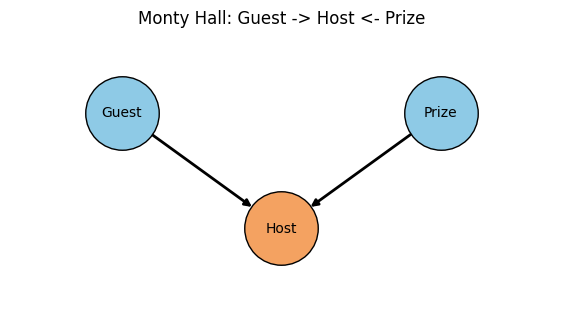

In [3]:
deseneaza(
    muchii=[("Guest", "Host"), ("Prize", "Host")],
    poz={"Guest": (0, 1), "Prize": (2, 1), "Host": (1, 0)},
    titlu="Monty Hall: Guest -> Host <- Prize",
    culori={"Host": "#f4a261"},
)

### Implementarea în `pgmpy`, pas cu pas

**Pasul 1 - structura grafului.** Declarăm muchiile: `Guest → Host` şi `Prize → Host`.

**Pasul 2 - tabelele pentru nodurile fără părinţi.** `Guest` şi `Prize` sunt uniforme: `[[1/3],[1/3],[1/3]]` (o coloană, trei rânduri, pentru uşile 0, 1, 2).

**Pasul 3 - tabelul lui `Host`.** Este tabelul mare, cu 3 rânduri (uşa deschisă) şi $3\times3 = 9$ coloane (toate perechile `(Guest, Prize)`). Regula prezentatorului:

- nu deschide uşa aleasă de concurent;
- nu deschide uşa cu premiul;
- dacă `Guest ≠ Prize`, mai rămâne o singură uşă posibilă, deci o deschide cu probabilitate $1$;
- dacă `Guest = Prize`, rămân două uşi posibile, deci alege oricare cu probabilitate $1/2$.

Coloanele sunt ordonate `(Guest, Prize)`: `(0,0), (0,1), (0,2), (1,0), ...`, iar ultima variabilă din `evidence` variază cel mai repede. Construim tabelul cu un ciclu, ca să nu greşim la scrierea manuală a celor 27 de valori.

In [4]:
usi = [0, 1, 2]

# structura grafului
monty = ReteaBayesiana([("Guest", "Host"), ("Prize", "Host")])

# nodurile fara parinti: uniforme
cpd_guest = TabularCPD("Guest", 3, [[1/3], [1/3], [1/3]])
cpd_prize = TabularCPD("Prize", 3, [[1/3], [1/3], [1/3]])

# P(Host | Guest, Prize): linii = usa deschisa, coloane = (Guest, Prize)
valori_host = np.zeros((3, 9))
col = 0
for guest in usi:
    for prize in usi:
        posibile = [u for u in usi if u != guest and u != prize]  # usile pe care le poate deschide
        for u in posibile:
            valori_host[u, col] = 1 / len(posibile)
        col += 1

cpd_host = TabularCPD("Host", 3, valori_host,
                      evidence=["Guest", "Prize"], evidence_card=[3, 3])

monty.add_cpds(cpd_guest, cpd_prize, cpd_host)
print("Modelul este valid:", monty.check_model())
print()
print(cpd_host)

Modelul este valid: True

+---------+----------+----------+-----+----------+----------+----------+
| Guest   | Guest(0) | Guest(0) | ... | Guest(2) | Guest(2) | Guest(2) |
+---------+----------+----------+-----+----------+----------+----------+
| Prize   | Prize(0) | Prize(1) | ... | Prize(0) | Prize(1) | Prize(2) |
+---------+----------+----------+-----+----------+----------+----------+
| Host(0) | 0.0      | 0.0      | ... | 0.0      | 1.0      | 0.5      |
+---------+----------+----------+-----+----------+----------+----------+
| Host(1) | 0.5      | 0.0      | ... | 1.0      | 0.0      | 0.5      |
+---------+----------+----------+-----+----------+----------+----------+
| Host(2) | 0.5      | 1.0      | ... | 0.0      | 0.0      | 0.0      |
+---------+----------+----------+-----+----------+----------+----------+


`check_model()` verifică structura (graf aciclic), că fiecare nod are tabel şi că **fiecare coloană din fiecare tabel însumează 1**. Întoarce `True` dacă totul este corect.

### Inferenţa

Folosim `VariableElimination`, care calculează exact $P(\text{variabilă} \mid \text{evidenţă})$ prin însumarea (eliminarea) variabilelor care nu apar în întrebare.

**Întrebarea clasică:** concurentul alege uşa 0, prezentatorul deschide uşa 2. Unde este premiul?

In [5]:
infer = VariableElimination(monty)

# fara nicio informatie, premiul e uniform
print("P(Prize) fara evidenta:")
print(tabel(infer.query(["Prize"], show_progress=False), "Prize"))

# Guest = 0, Host = 2  ->  P(Prize | Guest=0, Host=2)
post = infer.query(["Prize"], evidence={"Guest": 0, "Host": 2}, show_progress=False)
print()
print("P(Prize | Guest=0, Host=2):")
print(tabel(post, "Prize"))

P(Prize) fara evidenta:
0    0.3333
1    0.3333
2    0.3333
Name: probabilitate, dtype: float64

P(Prize | Guest=0, Host=2):
0    0.3333
1    0.6667
2    0.0000
Name: probabilitate, dtype: float64


### Interpretarea rezultatului

$$P(\text{Prize}=0 \mid G=0, H=2) = \tfrac13, \qquad P(\text{Prize}=1 \mid G=0, H=2) = \tfrac23, \qquad P(\text{Prize}=2 \mid G=0, H=2) = 0$$

- **Să rămâi** (uşa 0) câştigă cu $1/3$.
- **Să schimbi** (uşa 1, singura închisă rămasă) câştigă cu $2/3$.
- Uşa 2 are probabilitate $0$, evident, pentru că tocmai a fost deschisă.

**Verificare cu regula lui Bayes** (cu $G=0$, $H=2$ observate):

$$P(\text{Prize}=1 \mid G=0, H=2) = \frac{P(H=2 \mid G=0, \text{Prize}=1)\cdot P(\text{Prize}=1)}{\sum_p P(H=2 \mid G=0, \text{Prize}=p)\cdot P(\text{Prize}=p)} = \frac{1 \cdot \frac13}{\frac12\cdot\frac13 + 1\cdot\frac13 + 0\cdot\frac13} = \frac{1/3}{1/2} = \frac23$$

**Intuiţia:** când ai ales prima dată, aveai $1/3$ şanse să nimereşti. Gestul prezentatorului nu schimbă asta (el oricum deschide o uşă cu capră), dar **concentrează** cele $2/3$ rămase pe singura uşă pe care nu ai ales-o şi nu a fost deschisă.

### Verificare prin simulare

Jucăm de 100.000 de ori jocul, respectând regulile, şi comparăm cele două strategii.

Daca ramane: 0.3323  (teoretic 1/3 = 0.3333)
Daca schimba: 0.6670  (teoretic 2/3 = 0.6667)


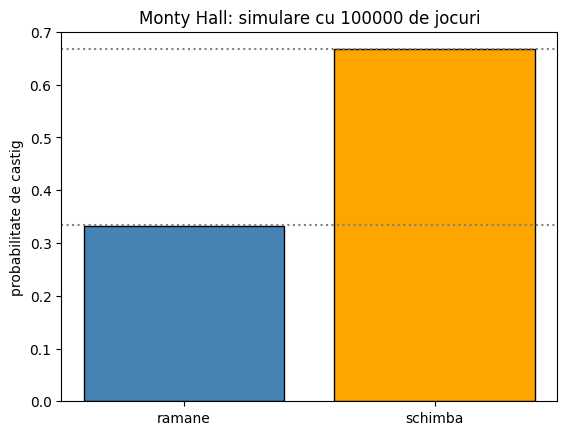

In [6]:
def joaca_monty(schimba, rng):
    premiu = rng.integers(3)
    ales = rng.integers(3)
    # prezentatorul deschide o usa care nu e a concurentului si nu are premiul
    posibile = [u for u in range(3) if u != ales and u != premiu]
    deschisa = rng.choice(posibile)
    if schimba:
        ales = [u for u in range(3) if u != ales and u != deschisa][0]
    return ales == premiu

rng = np.random.default_rng(12)
n = 100_000
castig_ramane = np.mean([joaca_monty(False, rng) for _ in range(n)])
castig_schimba = np.mean([joaca_monty(True, rng) for _ in range(n)])

print(f"Daca ramane: {castig_ramane:.4f}  (teoretic 1/3 = {1/3:.4f})")
print(f"Daca schimba: {castig_schimba:.4f}  (teoretic 2/3 = {2/3:.4f})")

plt.bar(["ramane", "schimba"], [castig_ramane, castig_schimba],
        color=["steelblue", "orange"], edgecolor="black")
plt.axhline(1/3, color="gray", linestyle=":")
plt.axhline(2/3, color="gray", linestyle=":")
plt.ylabel("probabilitate de castig")
plt.title("Monty Hall: simulare cu 100000 de jocuri")
plt.show()

## Exerciţiul 2: Diagnostic medical

Un medic vrea să determine probabilitatea ca un pacient să aibă o boală pulmonară ($B$), pornind de la simptome: tuse ($T$), dificultate de respiraţie ($D$) şi radiografie anormală ($X$). Toate variabilele sunt binare.

**Structura (din enunţ):**
- boala $B$ cauzează tusea $T$ şi radiografia anormală $X$: $B \to T$, $B \to X$;
- dificultatea de respiraţie depinde de boală **şi** de tuse: $B \to D$, $T \to D$.

**Tabelele de probabilităţi:**

| | |
|---|---|
| $P(B=1) = 0.1$ | $P(B=0) = 0.9$ |
| $P(T=1 \mid B=1) = 0.8$ | $P(T=1 \mid B=0) = 0.3$ |
| $P(X=1 \mid B=1) = 0.9$ | $P(X=1 \mid B=0) = 0.1$ |
| $P(D=1 \mid B=1, T=1) = 0.9$ | $P(D=1 \mid B=1, T=0) = 0.4$ |
| $P(D=1 \mid B=0, T=1) = 0.5$ | $P(D=1 \mid B=0, T=0) = 0.1$ |

Distribuţia comună se factorizează după graf:

$$P(B,T,X,D) = P(B)\,P(T\mid B)\,P(X\mid B)\,P(D\mid B,T)$$

### a) Definirea modelului în `pgmpy`

În `TabularCPD` rândurile sunt stările variabilei (rândul 0 = valoarea 0, rândul 1 = valoarea 1), iar coloanele sunt combinaţiile părinţilor. Enunţul dă $P(\cdot=1\mid\ldots)$, deci rândul 0 este complementul: $1 - P(\cdot = 1 \mid \ldots)$.

Pentru $D$, coloanele sunt ordonate $(B,T) = (0,0), (0,1), (1,0), (1,1)$ (ultimul părinte variază cel mai repede).

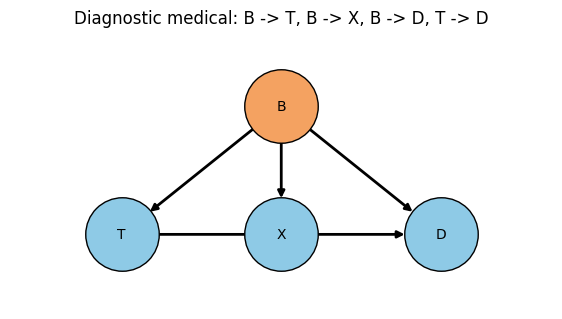

In [7]:
deseneaza(
    muchii=[("B", "T"), ("B", "X"), ("B", "D"), ("T", "D")],
    poz={"B": (1, 1.2), "T": (0, 0), "X": (1, 0), "D": (2, 0)},
    titlu="Diagnostic medical: B -> T, B -> X, B -> D, T -> D",
    culori={"B": "#f4a261"},
)

In [8]:
medical = ReteaBayesiana([("B", "T"), ("B", "X"), ("B", "D"), ("T", "D")])

cpd_B = TabularCPD("B", 2, [[0.9], [0.1]])

# coloane: B=0, B=1
cpd_T = TabularCPD("T", 2,
                   [[0.7, 0.2],      # P(T=0 | B)
                    [0.3, 0.8]],     # P(T=1 | B)
                   evidence=["B"], evidence_card=[2])

cpd_X = TabularCPD("X", 2,
                   [[0.9, 0.1],      # P(X=0 | B)
                    [0.1, 0.9]],     # P(X=1 | B)
                   evidence=["B"], evidence_card=[2])

# coloane: (B,T) = (0,0), (0,1), (1,0), (1,1)
cpd_D = TabularCPD("D", 2,
                   [[0.9, 0.5, 0.6, 0.1],   # P(D=0 | B,T)
                    [0.1, 0.5, 0.4, 0.9]],  # P(D=1 | B,T)
                   evidence=["B", "T"], evidence_card=[2, 2])

medical.add_cpds(cpd_B, cpd_T, cpd_X, cpd_D)
print("Modelul este valid:", medical.check_model())
print()
print(cpd_D)

Modelul este valid: True

+------+------+------+------+------+
| B    | B(0) | B(0) | B(1) | B(1) |
+------+------+------+------+------+
| T    | T(0) | T(1) | T(0) | T(1) |
+------+------+------+------+------+
| D(0) | 0.9  | 0.5  | 0.6  | 0.1  |
+------+------+------+------+------+
| D(1) | 0.1  | 0.5  | 0.4  | 0.9  |
+------+------+------+------+------+


### Independenţele din model

Inferenţa folosește independenţele condiţionate din graf. `pgmpy` le poate lista:

In [9]:
print(medical.get_independencies())

(T ⟂ X | B)
(D ⟂ X | B)


Rezultatul spune că $T \perp X \mid B$ şi $D \perp X \mid B$. În cuvinte: **dacă ştim dacă pacientul are boala, radiografia nu ne mai spune nimic despre tuse sau despre respiraţie.** Boala este cauza comună a simptomelor.

### b) Medicul observă tuse şi dificultăţi de respiraţie. Probabilitatea bolii?

In [10]:
infer2 = VariableElimination(medical)

post_B = infer2.query(["B"], evidence={"T": 1, "D": 1}, show_progress=False)
print("P(B | T=1, D=1):")
print(tabel(post_B, "B"))

P(B | T=1, D=1):
0    0.6522
1    0.3478
Name: probabilitate, dtype: float64


### c) Se află că pacientul NU avea boala. Probabilitatea unei radiografii anormale?

In [11]:
post_X = infer2.query(["X"], evidence={"B": 0}, show_progress=False)
print("P(X | B=0):")
print(tabel(post_X, "X"))

# daca pastram si simptomele observate, raspunsul ramane acelasi (X _||_ T, D | B)
post_X2 = infer2.query(["X"], evidence={"B": 0, "T": 1, "D": 1}, show_progress=False)
print()
print("P(X | B=0, T=1, D=1):")
print(tabel(post_X2, "X"))

# pentru comparatie, daca nu stim B, simptomele schimba P(X)
post_X3 = infer2.query(["X"], evidence={"T": 1, "D": 1}, show_progress=False)
print()
print("Pentru comparatie, P(X | T=1, D=1), fara sa stim B:")
print(tabel(post_X3, "X"))

P(X | B=0):
0    0.9
1    0.1
Name: probabilitate, dtype: float64

P(X | B=0, T=1, D=1):
0    0.9
1    0.1
Name: probabilitate, dtype: float64

Pentru comparatie, P(X | T=1, D=1), fara sa stim B:
0    0.6217
1    0.3783
Name: probabilitate, dtype: float64


### d) Calculul cu regula lui Bayes

#### Punctul b): $P(B=1 \mid T=1, D=1)$

Din formula lui Bayes:

$$P(B=1 \mid T=1, D=1) = \frac{P(B=1, T=1, D=1)}{P(T=1, D=1)}$$

Marginalizăm pe $X$ (care nu e observat). Din factorizare:

$$P(B,T,D) = \sum_{x} P(B)\,P(T\mid B)\,P(x\mid B)\,P(D\mid B,T) = P(B)\,P(T\mid B)\,P(D\mid B,T)\underbrace{\sum_x P(x\mid B)}_{=1}$$

Deci **$X$ dispare din calcul**: o variabilă neobservată care nu este părinte pentru nimic din întrebare nu influenţează răspunsul.

Calculăm numărătorul şi cele două cazuri din numitor:

$$P(B=1,T=1,D=1) = 0.1 \cdot 0.8 \cdot 0.9 = 0.072$$
$$P(B=0,T=1,D=1) = 0.9 \cdot 0.3 \cdot 0.5 = 0.135$$
$$P(T=1,D=1) = 0.072 + 0.135 = 0.207$$

$$\boxed{P(B=1 \mid T=1, D=1) = \frac{0.072}{0.207} = \frac{8}{23} \approx 0.3478}$$

**Interpretare:** apriori boala are $10\%$ şanse. După ce observăm tusea şi dificultatea de respiraţie, creşte la aproximativ $34.8\%$. Creşte mult (de peste 3 ori), dar rămâne sub 50%, pentru că simptomele apar des şi la oamenii sănătoşi ($P(T=1\mid B=0)=0.3$, $P(D=1\mid B=0,T=1)=0.5$) şi sănătoşii sunt mult mai mulţi.

#### Punctul c): $P(X=1 \mid B=0)$

Folosim independenţa condiţionată din graf. $X$ are un singur părinte, $B$, iar $T$ şi $D$ nu sunt descendenţi ai lui $X$, deci

$$X \perp \{T, D\} \mid B$$

Aşadar, odată ce ştim $B=0$, nu mai contează nimic altceva şi răspunsul este chiar intrarea din tabel:

$$\boxed{P(X=1 \mid B=0) = 0.1}$$

Fără independenţă am fi avut de calculat $P(X=1\mid B=0)$ prin însumări peste $T$ şi $D$, dar independenţa spune că ele se reduc la $1$. Codul de mai sus confirmă: $P(X=1 \mid B=0, T=1, D=1) = 0.1$ la fel.

**Contrast util:** dacă nu am şti $B$, simptomele ar conta. Radiografia ar fi anormală cu probabilitate
$$P(X=1\mid T=1,D=1) = \tfrac{8}{23}\cdot 0.9 + \tfrac{15}{23}\cdot 0.1 \approx 0.3783,$$
adică simptomele cresc şansa unei radiografii anormale *doar prin intermediul bolii* (de aceea dependenţa dispare când ştim $B$). Ponderile sunt $P(B=1\mid T=1,D=1) = \tfrac{8}{23}$ şi $P(B=0\mid T=1,D=1) = \tfrac{15}{23}$.

In [12]:
# verificare manuala a calculelor din Bayes (fara pgmpy)
pB = {1: 0.1, 0: 0.9}
pT1 = {1: 0.8, 0: 0.3}
pD1 = {(1, 1): 0.9, (1, 0): 0.4, (0, 1): 0.5, (0, 0): 0.1}   # P(D=1 | B, T)

b1 = pB[1] * pT1[1] * pD1[(1, 1)]    # P(B=1, T=1, D=1)
b0 = pB[0] * pT1[0] * pD1[(0, 1)]    # P(B=0, T=1, D=1)
print(f"P(B=1,T=1,D=1) = {b1:.4f},  P(B=0,T=1,D=1) = {b0:.4f}")
print(f"P(B=1 | T=1, D=1) = {b1 / (b1 + b0):.4f}  (8/23 = {8/23:.4f})")
print(f"P(X=1 | B=0) = 0.1  (direct din tabel, prin independenta)")

P(B=1,T=1,D=1) = 0.0720,  P(B=0,T=1,D=1) = 0.1350
P(B=1 | T=1, D=1) = 0.3478  (8/23 = 0.3478)
P(X=1 | B=0) = 0.1  (direct din tabel, prin independenta)


## Exerciţiul 3: Jocul dintre $J_0$ şi $J_1$

### Regulile jocului

1. Se aruncă o monedă **normală** pentru a decide cine începe ($J_0$ sau $J_1$).
2. **Runda 1:** jucătorul desemnat aruncă cu zarul lui (normal); obţine $n \in \{1,\dots,6\}$.
3. **Runda 2:** celălalt jucător aruncă moneda **lui** de $2n$ ori; obţine $m$ steme.
4. **Câştigă** jucătorul din runda 1 dacă $n \ge m$, altfel câştigă cel din runda 2.

Moneda lui $J_0$ este normală ($p=1/2$), iar moneda lui $J_1$ este măsluită ($p = 4/7$ pentru stemă).

**Observaţie de modelare.** Numărul de steme $m$ într-o rundă 2 este, dat $n$ şi jucătorul care aruncă, o variabilă binomială:

$$m \mid (n, \text{jucătorul care aruncă}) \sim \text{Binomial}\big(2n,\ p_{\text{jucător}}\big), \qquad p_{J_0} = \tfrac12,\ \ p_{J_1} = \tfrac47$$

### a) Estimare prin simulare a 10000 de jocuri

In [13]:
p_moneda = {0: 1/2, 1: 4/7}    # P(stema) pentru moneda lui J0, respectiv J1

def simuleaza_jocuri(n_jocuri):
    start = np.random.randint(0, 2, size=n_jocuri)       # cine incepe (moneda normala): 0 -> J0, 1 -> J1
    n = np.random.randint(1, 7, size=n_jocuri)           # zarul din runda 1 (normal)
    al_doilea = 1 - start                                # jucatorul care arunca moneda in runda 2
    p = np.where(al_doilea == 0, p_moneda[0], p_moneda[1])
    m = np.random.binomial(2 * n, p)                     # steme in 2n aruncari
    primul_castiga = (n >= m)
    castigator = np.where(primul_castiga, start, al_doilea)
    return start, n, m, castigator

start, n_z, m_s, castigator = simuleaza_jocuri(10_000)
p_J0 = np.mean(castigator == 0)
p_J1 = np.mean(castigator == 1)
print(f"J0 castiga in {p_J0:.4f} dintre jocuri")
print(f"J1 castiga in {p_J1:.4f} dintre jocuri")
print("Are sanse mai mari:", "J1" if p_J1 > p_J0 else "J0")

J0 castiga in 0.4235 dintre jocuri
J1 castiga in 0.5765 dintre jocuri
Are sanse mai mari: J1


Rezultatul este un pic afectat de zgomot: cu 10000 de jocuri, abaterea standard a estimării este $\sqrt{0.25/10000} = 0.005$, adică ±0.5%. Ca să fim siguri, calculăm şi valoarea **exactă** (prin însumare peste toate cazurile) şi repetăm simularea cu un număr mult mai mare de jocuri.

P(J0 castiga | J0 incepe) = 0.5145
P(J1 castiga | J1 incepe) = 0.6611

Exact:               P(J0 castiga) = 0.4267,  P(J1 castiga) = 0.5733
Simulare 2.000.000:  P(J0 castiga) = 0.4268,  P(J1 castiga) = 0.5732
Simulare 10.000:     P(J0 castiga) = 0.4235,  P(J1 castiga) = 0.5765


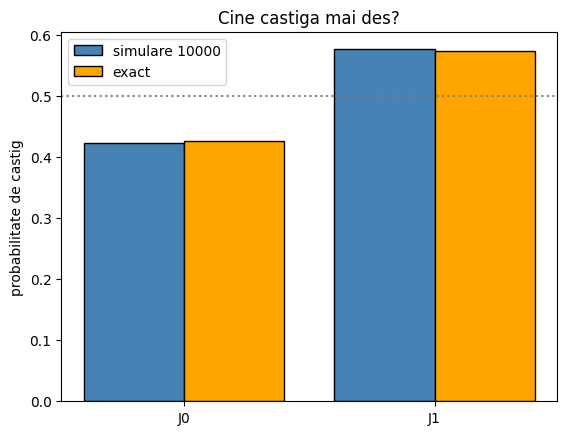

In [14]:
def prob_primul_castiga(p):
    # P(n >= m) cand al doilea jucator are moneda cu probabilitatea p de stema
    return sum((1/6) * sum(binom.pmf(m, 2 * n, p) for m in range(0, n + 1))
               for n in range(1, 7))

# J0 incepe -> J1 arunca moneda lui (p=4/7); J1 incepe -> J0 arunca moneda lui (p=1/2)
J0_castiga_cand_incepe = prob_primul_castiga(p_moneda[1])
J1_castiga_cand_incepe = prob_primul_castiga(p_moneda[0])

exact_J0 = 0.5 * J0_castiga_cand_incepe + 0.5 * (1 - J1_castiga_cand_incepe)
exact_J1 = 1 - exact_J0

print(f"P(J0 castiga | J0 incepe) = {J0_castiga_cand_incepe:.4f}")
print(f"P(J1 castiga | J1 incepe) = {J1_castiga_cand_incepe:.4f}")
print()
print(f"Exact:               P(J0 castiga) = {exact_J0:.4f},  P(J1 castiga) = {exact_J1:.4f}")

_, _, _, c_mare = simuleaza_jocuri(2_000_000)
print(f"Simulare 2.000.000:  P(J0 castiga) = {np.mean(c_mare == 0):.4f},  P(J1 castiga) = {np.mean(c_mare == 1):.4f}")
print(f"Simulare 10.000:     P(J0 castiga) = {p_J0:.4f},  P(J1 castiga) = {p_J1:.4f}")

x = np.arange(2)
plt.bar(x - 0.2, [p_J0, p_J1], width=0.4, label="simulare 10000", color="steelblue", edgecolor="black")
plt.bar(x + 0.2, [exact_J0, exact_J1], width=0.4, label="exact", color="orange", edgecolor="black")
plt.xticks(x, ["J0", "J1"])
plt.ylabel("probabilitate de castig")
plt.axhline(0.5, color="gray", linestyle=":")
plt.title("Cine castiga mai des?")
plt.legend()
plt.show()

**Concluzie la a):** $J_1$ are şansele mai mari de câştig (aproximativ $57\%$ faţă de $43\%$).

**De ce?** Cine joacă primul are un avantaj (câştigă dacă $n \ge m$, iar $m$ are media $2n\,p$, apropiată de $n$ când moneda e normală). Dar avantajul depinde de moneda adversarului:

- Când $J_1$ începe, el înfruntă moneda **normală** a lui $J_0$, deci câştigă în aproximativ $66\%$ din cazuri.
- Când $J_0$ începe, el înfruntă moneda **măsluită** a lui $J_1$, care dă mai multe steme ($m$ mai mare în medie), deci $J_0$ câştigă doar în aproximativ $51\%$ din cazuri.

Pe scurt, $J_1$ are avantaj pentru că adversarul lui, $J_0$, are moneda normală (inofensivă), în timp ce $J_0$ trebuie să înfrunte o monedă care dă multe steme.

### b) Reţeaua bayesiană

Variabilele reţelei:

- **Start** $\in\{0,1\}$ - cine începe ($0 = J_0$, $1 = J_1$); uniformă;
- **N** $\in\{1,\dots,6\}$ - rezultatul zarului din runda 1; uniformă (ambele zaruri sunt normale, deci nu depinde de cine începe);
- **M** $\in\{0,\dots,12\}$ - numărul de steme din runda 2 ($2n \le 12$). Depinde de **Start** (cine aruncă moneda: celălalt decât cine a început) şi de **N** (de câte ori se aruncă);
- **Castigator** $\in\{0,1\}$ - câştigătorul. Este o funcţie deterministă de `Start`, `N` şi `M`.

Graful:
$$\text{Start} \to M,\quad N \to M,\quad \text{Start}\to \text{Castigator},\quad N \to \text{Castigator},\quad M \to \text{Castigator}$$

Tabelele:

$$P(\text{Start}=s) = \tfrac12, \qquad P(N=n) = \tfrac16$$
$$P(M=m \mid \text{Start}=s, N=n) = \binom{2n}{m}\,p^m(1-p)^{2n-m}, \quad p = p_{\text{jucătorul care aruncă în runda 2}}$$

unde dacă `Start=0` (începe $J_0$) moneda aruncată este cea a lui $J_1$ ($p=4/7$), iar dacă `Start=1` este cea a lui $J_0$ ($p=1/2$).

$$\text{Castigator} = \begin{cases}\text{Start} & \text{dacă } N \ge M\\ 1-\text{Start} & \text{dacă } N < M\end{cases}$$

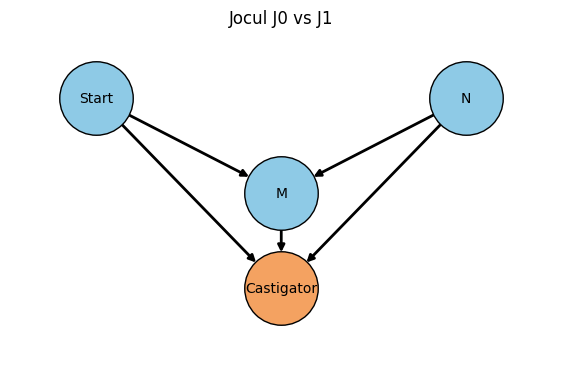

In [15]:
deseneaza(
    muchii=[("Start", "M"), ("N", "M"), ("Start", "Castigator"), ("N", "Castigator"), ("M", "Castigator")],
    poz={"Start": (0, 2), "N": (3, 2), "M": (1.5, 1), "Castigator": (1.5, 0)},
    titlu="Jocul J0 vs J1",
    culori={"Castigator": "#f4a261"},
    figsize=(7, 4.2),
)

In [16]:
zaruri = [1, 2, 3, 4, 5, 6]
valori_M = list(range(13))           # numarul de steme: 0..12

joc = ReteaBayesiana([("Start", "M"), ("N", "M"),
                      ("Start", "Castigator"), ("N", "Castigator"), ("M", "Castigator")])

cpd_start = TabularCPD("Start", 2, [[0.5], [0.5]], state_names={"Start": [0, 1]})
cpd_n = TabularCPD("N", 6, [[1/6]] * 6, state_names={"N": zaruri})

# P(M | Start, N): 13 randuri (valori m), 12 coloane (Start, N), N variaza cel mai repede
val_M = np.zeros((13, 12))
col = 0
for s in (0, 1):
    p = p_moneda[1 - s]                      # moneda jucatorului care arunca in runda 2
    for n in zaruri:
        for m in valori_M:
            val_M[m, col] = binom.pmf(m, 2 * n, p)   # 0 daca m > 2n
        col += 1
cpd_M = TabularCPD("M", 13, val_M, evidence=["Start", "N"], evidence_card=[2, 6],
                   state_names={"M": valori_M, "Start": [0, 1], "N": zaruri})

# P(Castigator | Start, N, M): 2 randuri, 2*6*13 = 156 coloane, M variaza cel mai repede
val_C = np.zeros((2, 2 * 6 * 13))
col = 0
for s in (0, 1):
    for n in zaruri:
        for m in valori_M:
            castigator_c = s if n >= m else 1 - s
            val_C[castigator_c, col] = 1.0
            col += 1
cpd_C = TabularCPD("Castigator", 2, val_C, evidence=["Start", "N", "M"], evidence_card=[2, 6, 13],
                   state_names={"Castigator": [0, 1], "Start": [0, 1], "N": zaruri, "M": valori_M})

joc.add_cpds(cpd_start, cpd_n, cpd_M, cpd_C)
print("Modelul este valid:", joc.check_model())

Modelul este valid: True


**Verificare a modelului prin inferenţă.** Dacă reţeaua este corectă, probabilitatea marginală a câştigătorului trebuie să coincidă cu valoarea exactă de la punctul a).

In [17]:
infer3 = VariableElimination(joc)

castig = infer3.query(["Castigator"], show_progress=False)
print("P(Castigator) din retea:")
print(tabel(castig, "Castigator"))
print(f"Exact (calcul direct): J0 = {exact_J0:.4f}, J1 = {exact_J1:.4f}")

P(Castigator) din retea:
0    0.4267
1    0.5733
Name: probabilitate, dtype: float64
Exact (calcul direct): J0 = 0.4267, J1 = 0.5733


### c) Cine e cel mai probabil să fi început, ştiind că în runda 2 s-a obţinut o singură stemă?

Evidenţa este $M = 1$ şi vrem $P(\text{Start} \mid M=1)$.

**Calcul cu regula lui Bayes:**

$$P(\text{Start}=s \mid M=1) = \frac{P(M=1 \mid \text{Start}=s)\,P(\text{Start}=s)}{\sum_{s'} P(M=1 \mid \text{Start}=s')\,P(\text{Start}=s')}$$

Verosimilitatea $P(M=1 \mid \text{Start}=s)$ se obţine marginalizând zarul $N$:

$$P(M=1 \mid \text{Start}=s) = \sum_{n=1}^{6} \frac16 \binom{2n}{1}\, p_s (1-p_s)^{2n-1} = \frac16\sum_{n=1}^{6} 2n\, p_s (1-p_s)^{2n-1}$$

- $s = 0$ ($J_0$ începe, deci $J_1$ aruncă moneda cu $p=\frac47$): $P(M=1 \mid \text{Start}=0) \approx 0.1225$
- $s = 1$ ($J_1$ începe, deci $J_0$ aruncă moneda cu $p=\frac12$): $P(M=1 \mid \text{Start}=1) \approx 0.1479$

Cum apriori $P(\text{Start}=s)=\frac12$, acest factor se simplifică:

$$P(\text{Start}=0 \mid M=1) = \frac{0.1225}{0.1225+0.1479} \approx 0.4529, \qquad P(\text{Start}=1 \mid M=1) \approx 0.5471$$

**Intuiţia:** moneda lui $J_1$ este încărcată spre stemă, deci produce de obicei *multe* steme. A obţine **doar una** (un rezultat mic) este mai puţin probabil cu moneda lui $J_1$ decât cu moneda normală a lui $J_0$. Prin urmare, observarea lui $M=1$ sugerează uşor că moneda aruncată în runda 2 a fost cea normală, adică a lui $J_0$, deci că **$J_1$ a început**. Raportul de verosimilitate este $0.1479 / 0.1225 \approx 1.21$, modest, de aceea concluzia este slabă ($54.7\%$).

In [18]:
# inferenta in retea
post_start = infer3.query(["Start"], evidence={"M": 1}, show_progress=False)
print("P(Start | M=1) din retea  (0 = J0 a inceput, 1 = J1 a inceput):")
print(tabel(post_start, "Start"))

# verificare manuala cu regula lui Bayes
veros = {s: sum((1/6) * binom.pmf(1, 2 * n, p_moneda[1 - s]) for n in zaruri) for s in (0, 1)}
print()
print(f"P(M=1 | Start=0) = {veros[0]:.4f},  P(M=1 | Start=1) = {veros[1]:.4f}")
print(f"P(Start=0 | M=1) = {veros[0] / (veros[0] + veros[1]):.4f}")
print(f"P(Start=1 | M=1) = {veros[1] / (veros[0] + veros[1]):.4f}")

# verificare prin simulare: din cate jocuri cu M=1 a inceput J0?
start_m, _, m_m, _ = simuleaza_jocuri(3_000_000)
print(f"\nSimulare (3.000.000 jocuri, {np.sum(m_m == 1)} cu M=1): P(Start=0 | M=1) ~ {np.mean(start_m[m_m == 1] == 0):.4f}")

print()
print("Cel mai probabil a inceput:", "J1" if post_start.values[1] > post_start.values[0] else "J0")

P(Start | M=1) din retea  (0 = J0 a inceput, 1 = J1 a inceput):
0    0.4529
1    0.5471
Name: probabilitate, dtype: float64

P(M=1 | Start=0) = 0.1225,  P(M=1 | Start=1) = 0.1479
P(Start=0 | M=1) = 0.4529
P(Start=1 | M=1) = 0.5471

Simulare (3.000.000 jocuri, 404714 cu M=1): P(Start=0 | M=1) ~ 0.4529

Cel mai probabil a inceput: J1


## Concluzii

- **Ex. 1.** Reţeaua $\text{Guest}\to\text{Host}\leftarrow\text{Prize}$ explică paradoxul: dacă schimbi uşa, câştigi cu $2/3$; dacă rămâi, cu $1/3$. Simularea cu 100000 de jocuri confirmă.
- **Ex. 2.** $P(B=1\mid T=1, D=1) = 8/23 \approx 34.8\%$, iar $P(X=1\mid B=0) = 0.1$, pentru că $X \perp \{T,D\} \mid B$.
- **Ex. 3.** $J_1$ câştigă mai des ($\approx 57.3\%$). Dacă în runda 2 s-a obţinut o singură stemă, e mai probabil ca $J_1$ să fi început ($\approx 54.7\%$).